In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [19]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv(list(uploaded.keys())[0])

print("Dataset loaded successfully!")

Saving StudentPerformanceFactors.csv to StudentPerformanceFactors (2).csv
Dataset loaded successfully!


# New section

In [20]:
# First 5 rows
print("First 5 rows:")
display(df.head())

# Last 5 rows
print("Last 5 rows:")
display(df.tail())

# Dataset shape
print("Dataset shape:", df.shape)

# Column names
print("Column names:")
print(df.columns)

# Data types
print("Data types:")
print(df.dtypes)

# Dataset information
df.info()

First 5 rows:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


Last 5 rows:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68
6606,15,67,Medium,Low,Yes,9,94,Medium,Yes,0,Medium,Medium,Public,Positive,4,No,Postgraduate,Near,Male,64


Dataset shape: (6607, 20)
Column names:
Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='object')
Data types:
Hours_Studied                  int64
Attendance                     int64
Parental_Involvement          object
Access_to_Resources           object
Extracurricular_Activities    object
Sleep_Hours                    int64
Previous_Scores                int64
Motivation_Level              object
Internet_Access               object
Tutoring_Sessions              int64
Family_Income                 object
Teacher_Quality               object
School_Type                   object
Peer

In [21]:
numerical = df.select_dtypes(include=np.number).columns

categorical = df.select_dtypes(include='object').columns

print("Numerical columns:")
print(list(numerical))

print("\nCategorical columns:")
print(list(categorical))

Numerical columns:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

Categorical columns:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


In [22]:
print("Numerical statistics:")
display(df.describe())

print("Categorical statistics:")
display(df.describe(include='object'))

Numerical statistics:


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


Categorical statistics:


,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
count,6607,6607,6607,6607,6607,6607,6529,6607,6607,6607,6517,6540,6607
unique,3,3,2,3,2,3,3,2,3,2,3,3,2
top,Medium,Medium,Yes,Medium,Yes,Low,Medium,Public,Positive,No,High School,Near,Male
freq,3362,3319,3938,3351,6108,2672,3925,4598,2638,5912,3223,3884,3814


In [23]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().sum() / len(df)) * 100
})

display(missing)

,Missing Values,Percentage
Hours_Studied,0,0.000000
Attendance,0,0.000000
Parental_Involvement,0,0.000000
Access_to_Resources,0,0.000000
Extracurricular_Activities,0,0.000000
Sleep_Hours,0,0.000000
Previous_Scores,0,0.000000
Motivation_Level,0,0.000000
Internet_Access,0,0.000000
Tutoring_Sessions,0,0.000000


In [24]:
# Create backup
df_clean = df.copy()

# Numerical missing values
for col in numerical:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Categorical missing values
for col in categorical:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64


In [25]:
# Create backup
df_clean = df.copy()

# Numerical missing values
for col in numerical:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Categorical missing values
for col in categorical:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64


In [26]:
print("Duplicate rows:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Duplicates after removal:", df_clean.duplicated().sum())

Duplicate rows: 0
Duplicates after removal: 0


In [27]:
# Remove extra spaces from categorical values
for col in categorical:
    df_clean[col] = df_clean[col].str.strip()

# Check unique categories
for col in categorical:
    print("\n", col)
    print(df_clean[col].unique())


 Parental_Involvement
['Low' 'Medium' 'High']

 Access_to_Resources
['High' 'Medium' 'Low']

 Extracurricular_Activities
['No' 'Yes']

 Motivation_Level
['Low' 'Medium' 'High']

 Internet_Access
['Yes' 'No']

 Family_Income
['Low' 'Medium' 'High']

 Teacher_Quality
['Medium' 'High' 'Low']

 School_Type
['Public' 'Private']

 Peer_Influence
['Positive' 'Negative' 'Neutral']

 Learning_Disabilities
['No' 'Yes']

 Parental_Education_Level
['High School' 'College' 'Postgraduate']

 Distance_from_Home
['Near' 'Moderate' 'Far']

 Gender
['Male' 'Female']


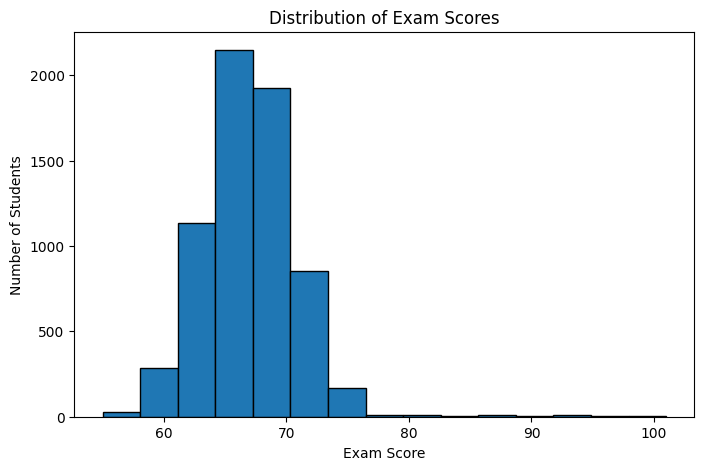

In [28]:
plt.figure(figsize=(8,5))

plt.hist(df_clean['Exam_Score'], bins=15, edgecolor='black')

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()

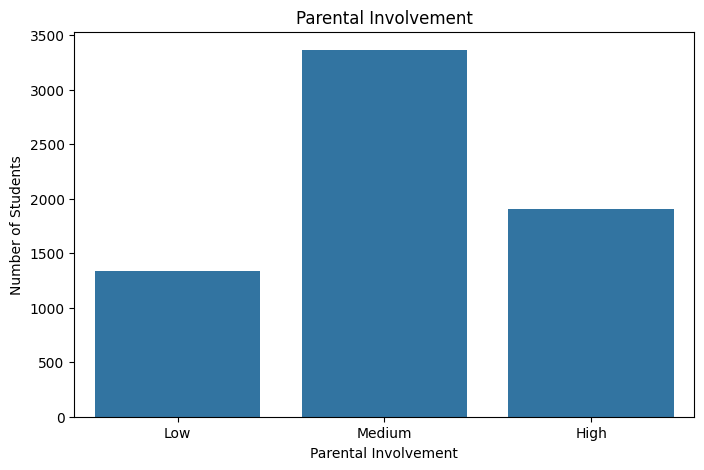

In [29]:
plt.figure(figsize=(8,5))

sns.countplot(data=df_clean, x='Parental_Involvement')

plt.title("Parental Involvement")
plt.xlabel("Parental Involvement")
plt.ylabel("Number of Students")

plt.show()

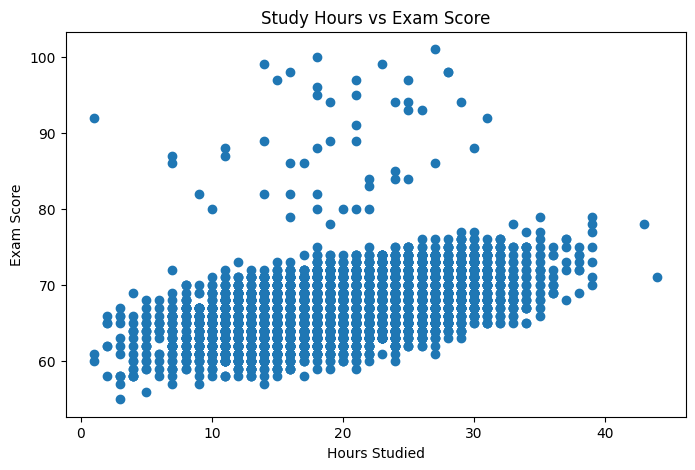

In [30]:
plt.figure(figsize=(8,5))

plt.scatter(df_clean['Hours_Studied'],
            df_clean['Exam_Score'])

plt.title("Study Hours vs Exam Score")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")

plt.show()

In [31]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=categorical,
    drop_first=True,
    dtype=int
)

print("Before encoding:", df_clean.shape)
print("After encoding:", df_encoded.shape)

display(df_encoded.head())

Before encoding: (6607, 20)
After encoding: (6607, 28)


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score,Parental_Involvement_Low,Parental_Involvement_Medium,Access_to_Resources_Low,...,Teacher_Quality_Medium,School_Type_Public,Peer_Influence_Neutral,Peer_Influence_Positive,Learning_Disabilities_Yes,Parental_Education_Level_High School,Parental_Education_Level_Postgraduate,Distance_from_Home_Moderate,Distance_from_Home_Near,Gender_Male
0,23,84,7,73,0,3,67,1,0,0,...,1,1,0,1,0,1,0,0,1,1
1,19,64,8,59,2,4,61,1,0,0,...,1,1,0,0,0,0,0,1,0,0
2,24,98,7,91,2,4,74,0,1,0,...,1,1,1,0,0,0,1,0,1,1
3,29,89,8,98,1,4,71,1,0,0,...,1,1,0,0,0,1,0,1,0,1
4,19,92,6,65,3,4,70,0,1,0,...,0,1,1,0,0,0,0,0,1,0


In [32]:
df_scaled = df_encoded.copy()

# Do not scale target column
target = 'Exam_Score'

scale_columns = [
    col for col in numerical
    if col != target and col in df_scaled.columns
]

scaler = StandardScaler()

df_scaled[scale_columns] = scaler.fit_transform(
    df_scaled[scale_columns]
)

print("Scaling completed!")
display(df_scaled.head())

Scaling completed!


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score,Parental_Involvement_Low,Parental_Involvement_Medium,Access_to_Resources_Low,...,Teacher_Quality_Medium,School_Type_Public,Peer_Influence_Neutral,Peer_Influence_Positive,Learning_Disabilities_Yes,Parental_Education_Level_High School,Parental_Education_Level_Postgraduate,Distance_from_Home_Moderate,Distance_from_Home_Near,Gender_Male
0,0.504942,0.348375,-0.019796,-0.143800,-1.213934,0.031411,67,1,0,0,...,1,1,0,1,0,1,0,0,1,1
1,-0.162822,-1.383736,0.661399,-1.116110,0.411451,1.001199,61,1,0,0,...,1,1,0,0,0,0,0,1,0,0
2,0.671882,1.560853,-0.019796,1.106313,0.411451,1.001199,74,0,1,0,...,1,1,1,0,0,0,1,0,1,1
3,1.506587,0.781403,0.661399,1.592469,-0.401242,1.001199,71,1,0,0,...,1,1,0,0,0,1,0,1,0,1
4,-0.162822,1.041220,-0.700990,-0.699406,1.224144,1.001199,70,0,1,0,...,0,1,1,0,0,0,0,0,1,0


In [33]:
print("Final dataset shape:", df_scaled.shape)

print("Missing values:",
      df_scaled.isnull().sum().sum())

print("Duplicate rows:",
      df_scaled.duplicated().sum())

display(df_scaled.head(10))

Final dataset shape: (6607, 28)
Missing values: 0
Duplicate rows: 0


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score,Parental_Involvement_Low,Parental_Involvement_Medium,Access_to_Resources_Low,...,Teacher_Quality_Medium,School_Type_Public,Peer_Influence_Neutral,Peer_Influence_Positive,Learning_Disabilities_Yes,Parental_Education_Level_High School,Parental_Education_Level_Postgraduate,Distance_from_Home_Moderate,Distance_from_Home_Near,Gender_Male
0,0.504942,0.348375,-0.019796,-0.143800,-1.213934,0.031411,67,1,0,0,...,1,1,0,1,0,1,0,0,1,1
1,-0.162822,-1.383736,0.661399,-1.116110,0.411451,1.001199,61,1,0,0,...,1,1,0,0,0,0,0,1,0,0
2,0.671882,1.560853,-0.019796,1.106313,0.411451,1.001199,74,0,1,0,...,1,1,1,0,0,0,1,0,1,1
3,1.506587,0.781403,0.661399,1.592469,-0.401242,1.001199,71,1,0,0,...,1,1,0,0,0,1,0,1,0,1
4,-0.162822,1.041220,-0.700990,-0.699406,1.224144,1.001199,70,0,1,0,...,0,1,1,0,0,0,0,0,1,0
5,-0.162822,0.694798,0.661399,0.967412,1.224144,0.031411,71,0,1,0,...,1,1,0,1,0,0,1,0,1,1
6,1.506587,0.348375,-0.019796,-0.491054,-0.401242,-0.938377,67,0,1,1,...,1,0,1,0,0,1,0,1,0,1
7,0.838823,-0.171258,-0.700990,-1.741167,-0.401242,-0.938377,66,1,0,0,...,0,1,0,0,0,1,0,0,0,1
8,-0.496704,1.214431,-0.700990,0.342355,-1.213934,-1.908165,69,0,1,0,...,0,0,1,0,0,0,0,0,1,1
9,0.504942,1.560853,0.661399,-0.282701,-1.213934,1.970988,72,0,1,0,...,0,1,0,1,0,1,0,1,0,1


In [34]:
df_scaled.to_csv(
    'Prepared_Student_Performance.csv',
    index=False
)

print("Prepared dataset saved successfully!")

Prepared dataset saved successfully!


In [35]:
from google.colab import files

files.download('Prepared_Student_Performance.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>